# Problem 5

In [96]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)

11.173260452749583


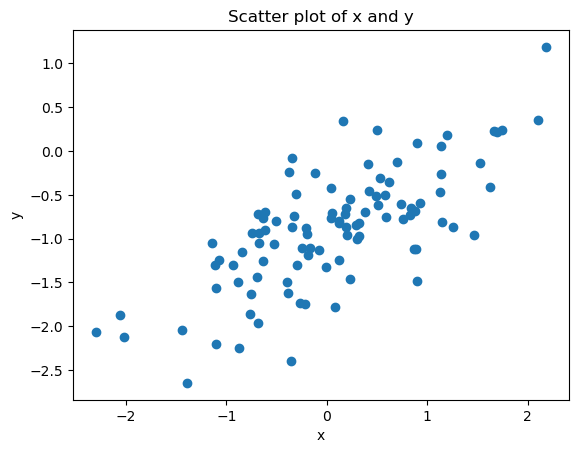

In [97]:
# 5a
x = np.random.normal(0, 1, 100)

# 5b
eps = np.random.normal(0, 0.5, 100)

# 5c
y = -1 + 0.5 * x + eps
print(np.linalg.norm(y))

# 5d
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter plot of x and y')
plt.show()

In [98]:
# 5e
import statsmodels.api as sm
results_e = sm.OLS(y, sm.add_constant(x)).fit()
print(results_e.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.522
Model:                            OLS   Adj. R-squared:                  0.517
Method:                 Least Squares   F-statistic:                     107.0
Date:                Mon, 19 Jan 2026   Prob (F-statistic):           2.20e-17
Time:                        17:35:02   Log-Likelihood:                -65.124
No. Observations:                 100   AIC:                             134.2
Df Residuals:                      98   BIC:                             139.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.9265      0.047    -19.717      0.0

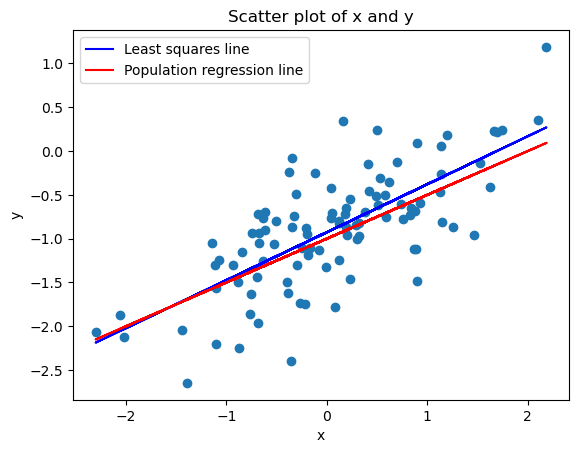

In [99]:
# 5f
pred = results_e.params[0] + results_e.params[1] * x
plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter plot of x and y')
plt.plot(x, pred, color='blue', label='Least squares line')
plt.plot(x, -1 + 0.5 * x, color='red', label='Population regression line')
plt.legend()
plt.show()

In [100]:
with_sqrs = np.column_stack((x, x**2))
sm.OLS(y, sm.add_constant(with_sqrs)).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      y   R-squared:                       0.522
Model:                            OLS   Adj. R-squared:                  0.512
Method:                 Least Squares   F-statistic:                     52.96
Date:                Mon, 19 Jan 2026   Prob (F-statistic):           2.83e-16
Time:                        17:35:02   Log-Likelihood:                -65.107
No. Observations:                 100   AIC:                             136.2
Df Residuals:                      97   BIC:                             144.0
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.9325      0.058    -16.158      0.000      -1.047      -0.818
x1             0.5468      0.053     10.229      0.000       0.441       0.653
x2             0.0077      0.043      0.181      0.856      -0.077       0.092
==============================================================================
Omnibus:                        0.893   Durbin-Watson:                   2.152
Prob(Omnibus):                  0.640   Jarque-Bera (JB):                0.552
Skew:                          -0.170   Prob(JB):                        0.759
Kurtosis:                       3.132   Cond. No.                         2.10
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

[-0.99876907  0.49589413]


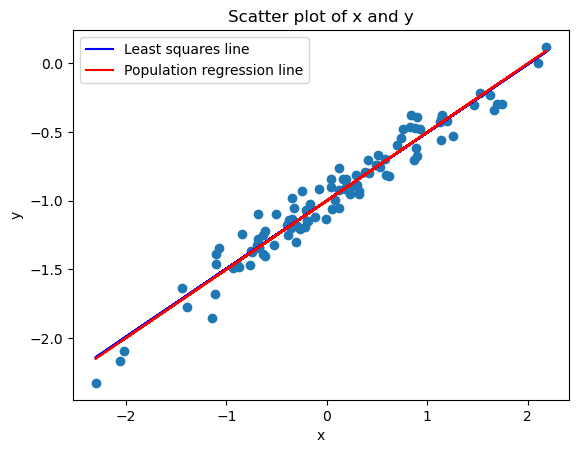

In [101]:
# 5h
eps = np.random.normal(0, 0.1, 100)
y = -1 + 0.5 * x + eps

model = sm.OLS(y, sm.add_constant(x))
results_h = model.fit()
coef = results_h.params
print(coef)

plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter plot of x and y')
plt.plot(x, coef[0] + coef[1] * x, color='blue', label='Least squares line')
plt.plot(x, -1 + 0.5 * x, color='red', label='Population regression line')
plt.legend()
plt.show()

[-1.01396172  0.39434713]


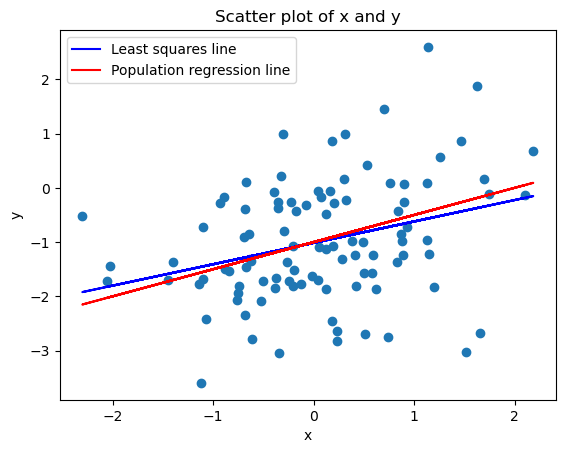

In [102]:
# 5h
eps = np.random.normal(0, 1, 100)
y = -1 + 0.5 * x + eps

model = sm.OLS(y, sm.add_constant(x))
results_i = model.fit()
coef = results_i.params
print(coef)

plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.title('Scatter plot of x and y')
plt.plot(x, coef[0] + coef[1] * x, color='blue', label='Least squares line')
plt.plot(x, -1 + 0.5 * x, color='red', label='Population regression line')
plt.legend()
plt.show()

In [103]:
# 5j
print(results_e.conf_int(alpha=0.05))
print(results_h.conf_int(alpha=0.05))
print(results_i.conf_int(alpha=0.05))

[[-1.01974096 -0.83324551]
 [ 0.44261338  0.65281376]]
[[-1.01894809 -0.97859004]
 [ 0.4731502   0.51863806]]
[[-1.22700729 -0.80091614]
 [ 0.15422192  0.63447234]]


# Problem 6

In [104]:
from ISLP import load_data
Boston = load_data('Boston')

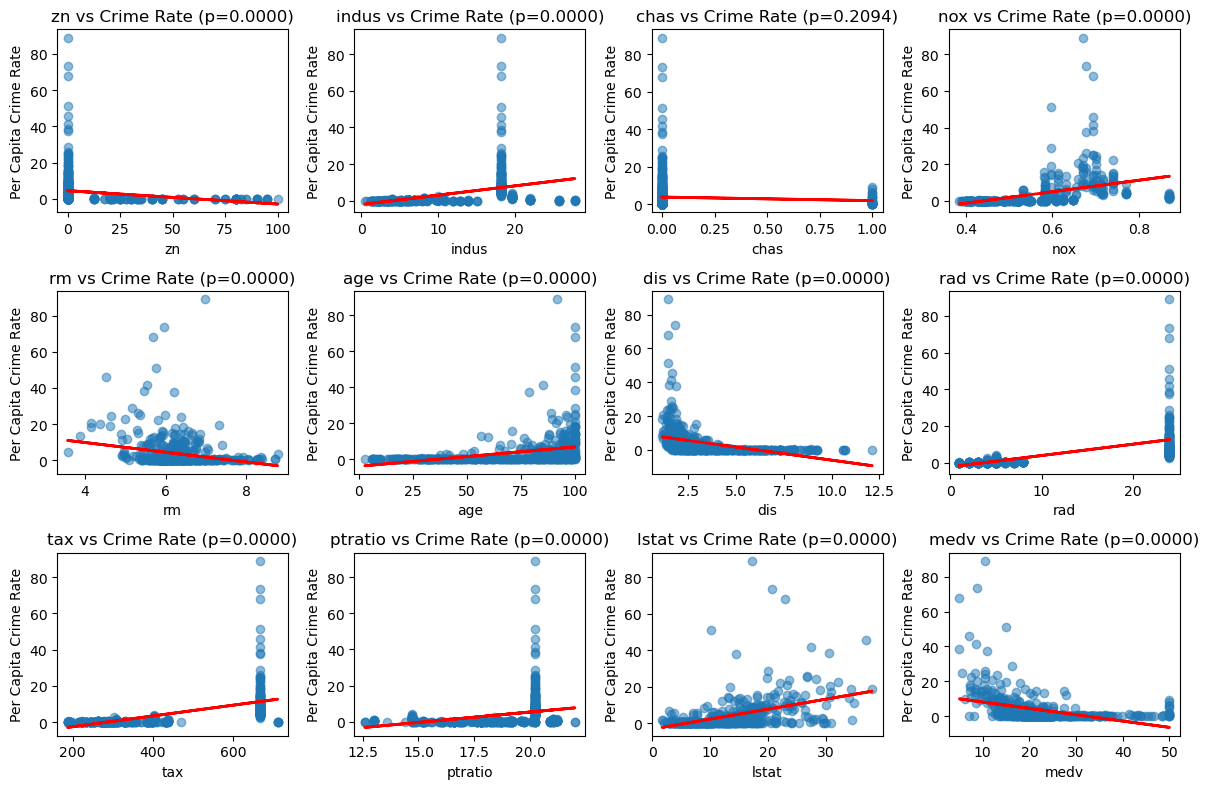

Statistically significant predictors: ['zn', 'indus', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'lstat', 'medv']


In [105]:
# 6a
significant_predictors = []
results_summary = []

fig, axs = plt.subplots(3, 4, figsize=(12, 8))

for i, col in enumerate(Boston.columns.drop('crim')):
    model = sm.OLS(Boston['crim'], sm.add_constant(Boston[col])).fit()
    p_value = model.pvalues[col]
    if p_value < 0.05:
        significant_predictors.append(col)
    
    results_summary.append({
        'Predictor': col,
        'Coefficient': model.params[col],
        'P-value': p_value,
        'R-squared': model.rsquared
    })
    
    ax = axs[i // 4, i % 4]
    ax.scatter(Boston[col], Boston['crim'], alpha=0.5)
    ax.plot(Boston[col], model.fittedvalues, 'r-', linewidth=2)
    ax.set_xlabel(col)
    ax.set_ylabel('Per Capita Crime Rate')
    ax.set_title(f'{col} vs Crime Rate (p={p_value:.4f})')

plt.tight_layout()
plt.show()

print("Statistically significant predictors:", significant_predictors)

In [106]:
# 6b
model = sm.OLS(Boston['crim'], sm.add_constant(Boston.drop('crim', axis=1))).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                   crim   R-squared:                       0.449
Model:                            OLS   Adj. R-squared:                  0.436
Method:                 Least Squares   F-statistic:                     33.52
Date:                Mon, 19 Jan 2026   Prob (F-statistic):           2.03e-56
Time:                        17:35:04   Log-Likelihood:                -1655.4
No. Observations:                 506   AIC:                             3337.
Df Residuals:                     493   BIC:                             3392.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         13.7784      7.082      1.946      0.0

C:\Users\issac\AppData\Local\Temp\ipykernel_20920\868500245.py:12: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.annotate(txt, (X[i], Y[i]))


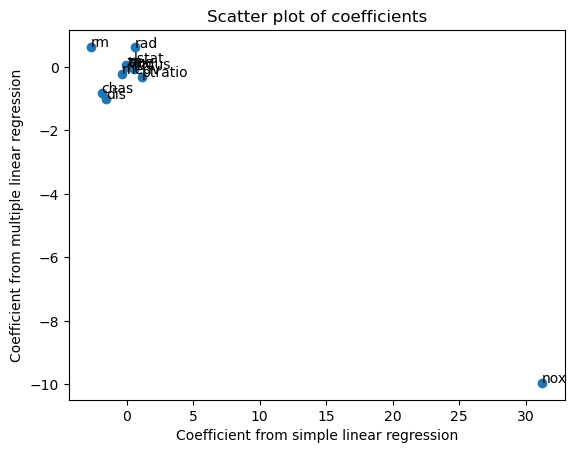

In [107]:
# 6c
X = [summary['Coefficient'] for summary in results_summary]
Y = model.params[1:]
txt = [summary['Predictor'] for summary in results_summary]

plt.scatter(X, Y)
plt.xlabel('Coefficient from simple linear regression')
plt.ylabel('Coefficient from multiple linear regression')
plt.title('Scatter plot of coefficients')

for i, txt in enumerate(txt):
    plt.annotate(txt, (X[i], Y[i]))

plt.show()

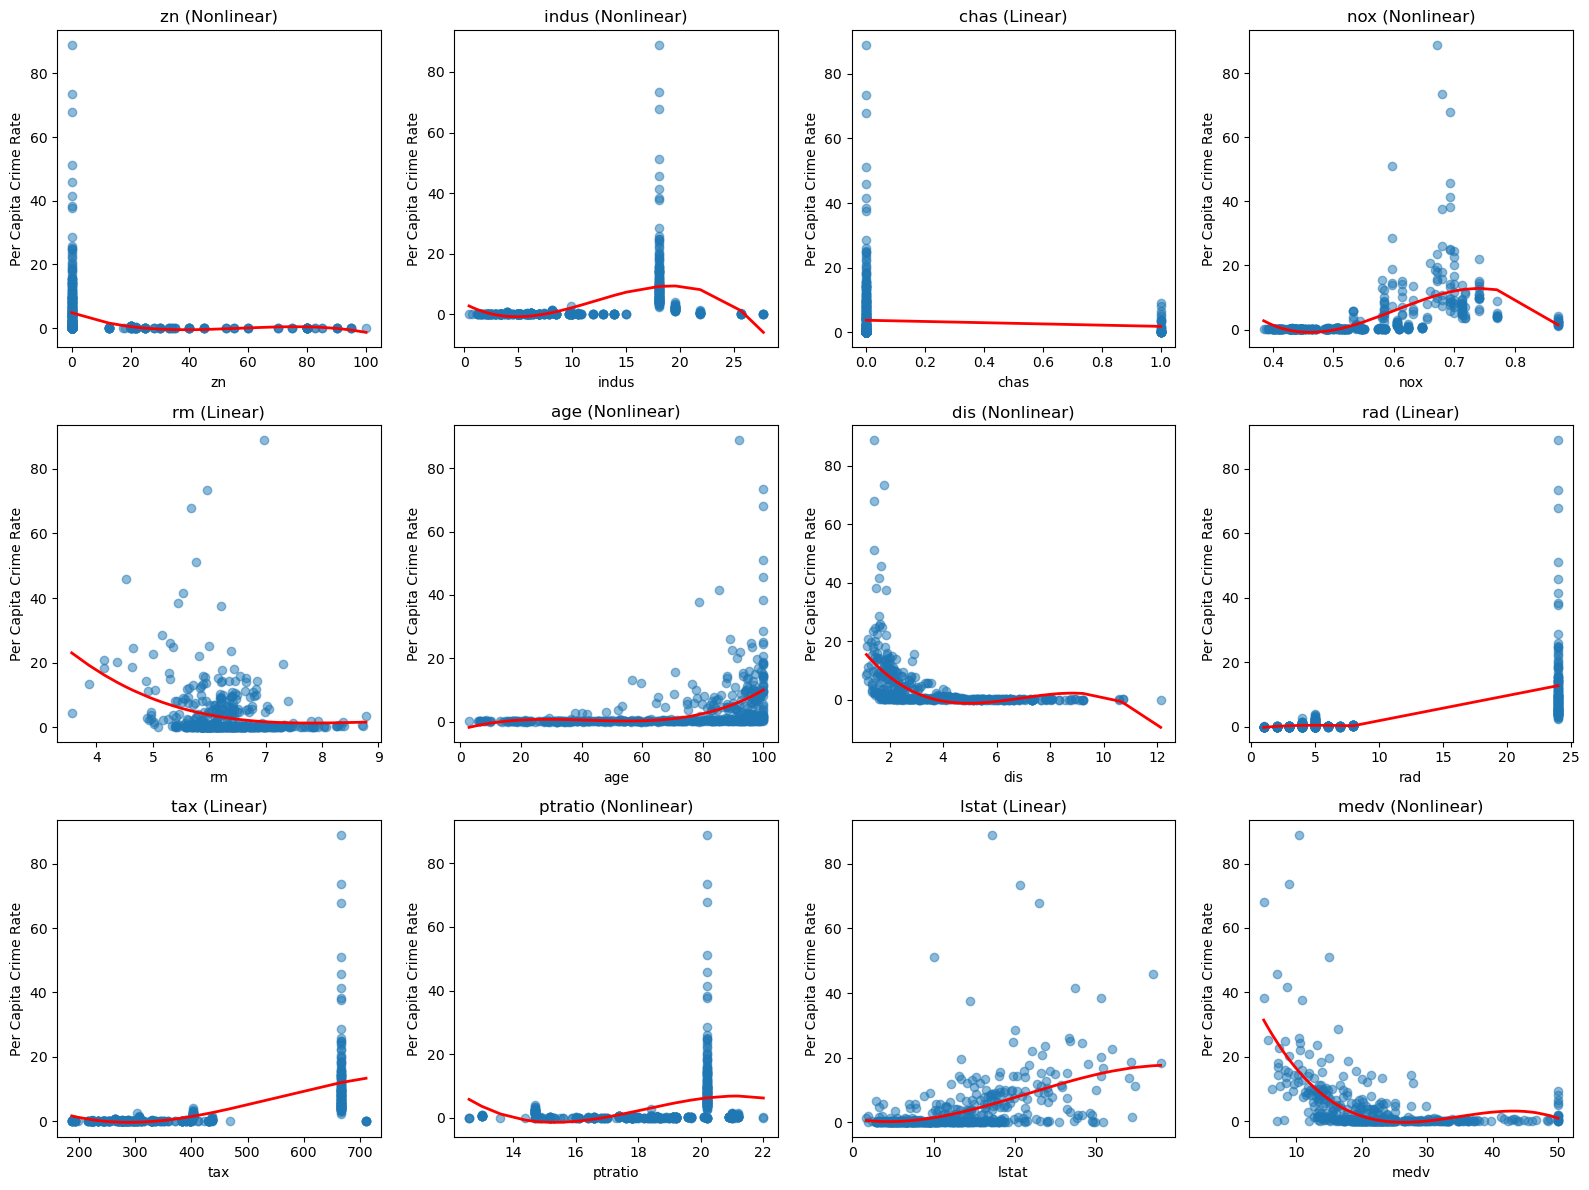

Predictors with evidence of non-linear association: ['zn', 'indus', 'nox', 'age', 'dis', 'ptratio', 'medv']


In [108]:
# 6d
nonlinear_predictors = []
fig, axs = plt.subplots(3, 4, figsize=(16, 12))

for i, col in enumerate(Boston.columns.drop('crim')):
    X = Boston[col].values
    X_poly = np.column_stack((X, X**2, X**3))
    
    model = sm.OLS(Boston['crim'], sm.add_constant(X_poly)).fit()
    
    p_x2 = model.pvalues.iloc[1]
    p_x3 = model.pvalues.iloc[2]
    is_nonlinear = p_x2 < 0.05 or p_x3 < 0.05
    
    if is_nonlinear:
        nonlinear_predictors.append(col)
    
    sort_idx = np.argsort(X)
    X_sorted = X[sort_idx]
    fitted_sorted = model.fittedvalues[sort_idx]
    
    ax = axs[i // 4, i % 4]
    ax.scatter(X, Boston['crim'], alpha=0.5)
    ax.plot(X_sorted, fitted_sorted, 'r-', linewidth=2)
    ax.set_xlabel(col)
    ax.set_ylabel('Per Capita Crime Rate')
    ax.set_title(f'{col} ({"Nonlinear" if is_nonlinear else "Linear"})')

plt.tight_layout()
plt.show()

print("Predictors with evidence of non-linear association:", nonlinear_predictors)